# Clasificación de Imágenes y Benchmark de Modelos: MNIST y CIFAR-10

### Descripción del proyecto

En este notebook desarrollo una comparativa práctica de modelos clásicos de Machine Learning (**k-Nearest Neighbors**, **Regresión Logística** y **SVM Lineal**) sobre dos conjuntos de datos de visión por computador con distinta complejidad:

1. **MNIST:** Dígitos manuscritos (28x28 píxeles en escala de grises, fondo limpio y trazo centrado).
2. **CIFAR-10:** Imágenes naturales en color (32x32 píxeles con variaciones de fondo, iluminación, perspectiva y textura).

El análisis abarca preprocesamiento y normalización, validación cruzada estratificada (3-fold CV), optimización de hiperparámetros con `GridSearchCV`, análisis de curvas de aprendizaje para diagnóstico de underfitting/overfitting, análisis de errores mediante matrices de confusión, interpretabilidad espacial de coeficientes y un estudio comparativo sobre los límites de los clasificadores lineales ante imágenes complejas.

**Autor:** Gonzalo Salvador

## 1. Carga y exploración del dataset MNIST

Utilizamos el dataset [MNIST](https://www.openml.org/d/554) de dígitos manuscritos (70,000 imágenes de 28x28 píxeles en escala de grises, correspondientes a 784 características numéricas). Descargamos el dataset directamente desde OpenML y visualizamos algunas muestras aleatorias con sus respectivas etiquetas de clase (0 al 9).

In [1]:
!pip install preamble

In [2]:
!pip install openml

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.4/160.4 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.8/93.8 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 41.7 MB/s eta 0:00:00
  Created wheel for liac-arff: filename=liac_arff-2.5.0-py3-none-any.whl size=11717 sha256=e474cbaffeac9066e98371ed44f8f9dcc0f2ae311be4327aca8ba55b0aaef25e
  Stored in directory: /root/.cache/pip/wheels/a9/ac/cf/c2919807a5c623926d217c0a18eb5b457e5c19d242c3b5963a
Successfully built liac-arff


In [3]:
# Imports generales
%matplotlib inline
from preamble import *
import matplotlib.pyplot as plt
plt.rcParams['savefig.dpi'] = 100 # Esto controla el tamanio de tus imagenes

In [4]:
import openml as oml

In [5]:
# Descarga de la data de MINST. Demora un poco la primera vez
import logging
logging.getLogger("openml").setLevel(logging.ERROR)

mnist = oml.datasets.get_dataset(554)
X, y, _, _ = mnist.get_data(target=mnist.default_target_attribute);
mnist_classes = {0:"Cero", 1: "Uno", 2: "Dos", 3: "Tres", 4: "Cuatro", 5: "Cinco",
                  6: "Seis", 7: "Siete", 8: "Ocho", 9: "Nueve"}

In [6]:
X

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69996,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


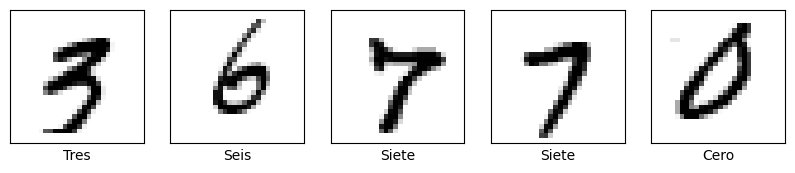

In [7]:
# Toma algunos ejemplos aleatorios, reescala las images al tamaño de 32x32 image y muestralas
from random import randint
fig, axes = plt.subplots(1, 5,  figsize=(10, 5))
for i in range(5):
    n = randint(0,70000)
    axes[i].imshow(X.values[n].reshape(28, 28), cmap=plt.cm.gray_r)
    axes[i].set_xlabel((mnist_classes[int(y.values[n])]))
    axes[i].set_xticks(()), axes[i].set_yticks(())
plt.show();

## 2. Comparativa inicial de clasificadores base

Evaluación de tres clasificadores con sus configuraciones por defecto sobre una submuestra estratificada del 10% (7,000 imágenes):
- **k-Nearest Neighbors (k-NN)**
- **Regresión Logística** (`max_iter=1000`)
- **SVM Lineal** (`LinearSVC`, `max_iter=5000`)

Se aplica validación cruzada estratificada de 3 folds, reportando la exactitud media (*accuracy*) y la desviación estándar para verificar la estabilidad de cada modelo.

**Enfoque**

Trabajamos sobre una submuestra estratificada del 10% (7000 imagenes) para que el costo de entrenamiento sea manejable manteniendo la proporcion original de cada digito. Los valores de los pixeles se llevan al rango [0, 1] dividiendo entre 255; esto ayuda a que la regresion logistica y el SVM lineal converjan mejor y deja las distancias de k-NN en una escala homogenea.

Comparamos los tres clasificadores con su configuracion por defecto usando validacion cruzada de 3 folds y reportamos la exactitud media junto con su desviacion estandar.

In [8]:
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

X_sub, _, y_sub, _ = train_test_split(X, y, train_size=0.10, stratify=y, random_state=42)
X_sub = X_sub.to_numpy(dtype=float) / 255.0
y_sub = y_sub.to_numpy()

clasificadores = {
    "k-NN": KNeighborsClassifier(),
    "Regresion Logistica": LogisticRegression(max_iter=1000),
    "SVM Lineal": LinearSVC(max_iter=5000),
}

for nombre, clf in clasificadores.items():
    scores = cross_val_score(clf, X_sub, y_sub, cv=3)
    print(f"{nombre:22s} accuracy = {scores.mean():.4f}  (+/- {scores.std():.4f})")

k-NN                   accuracy = 0.9339  (+/- 0.0039)
Regresion Logistica    accuracy = 0.8956  (+/- 0.0028)
SVM Lineal             accuracy = 0.8753  (+/- 0.0027)


**Resultados y discusion**

| Modelo | Accuracy (3-fold) | Desv. estandar |
|---|---|---|
| k-NN | 0.934 | 0.004 |
| Regresion Logistica | 0.896 | 0.003 |
| SVM Lineal | 0.875 | 0.003 |

k-NN es el mejor de los tres. En MNIST los digitos del mismo tipo forman grupos compactos en el espacio de pixeles, asi que un metodo basado en vecindad aprovecha muy bien esa estructura local. La regresion logistica y el SVM lineal quedan por debajo porque solo pueden trazar fronteras lineales sobre los pixeles crudos, algo demasiado rigido para separar diez clases con tanta variacion de trazo.

Las desviaciones estandar son muy pequenas (menos de 0.5%), de modo que el ranking se mantiene entre folds y la comparacion es confiable.

## 3. Ajuste de hiperparámetros con GridSearchCV y análisis de sesgo/varianza

Optimizamos el hiperparámetro principal de cada modelo mediante `GridSearchCV` con 3-fold cross-validation:
- **k-NN:** variando `n_neighbors` en `[1, 3, 5, 7, 9, 11, 15]`.
- **Regresión Logística:** variando `C` (inverso de la regularización L2) en escala logarítmica `[0.001, 0.01, 0.1, 1, 10, 100]`.
- **SVM Lineal:** variando `C` en `[0.001, 0.01, 0.1, 1, 10, 100]`.

Se grafican los scores de entrenamiento y prueba para diagnosticar de forma visual las zonas de **underfitting** y **overfitting**.

In [9]:
# Puede utilizar este gráfico genérico para  la búsqueda en 1D (1D grid search)
# grid_search: el resultado del GridSearchCV
# param_name: el nombre del parámetro que se está variando
def plot_tuning(grid_search, param_name):
    plt.figure()
    plt.plot(grid_search.param_grid[param_name], grid_search.cv_results_['mean_test_score'], marker = '.', label = 'Test score')
    plt.plot(grid_search.param_grid[param_name], grid_search.cv_results_['mean_train_score'], marker = '.', label = 'Train score')
    ax = plt.gca()
    ax.set_ylabel('score (ACC)')
    ax.set_xlabel(param_name)
    ax.legend()
    plt.title(grid_search.best_estimator_.__class__.__name__)
    print('Best configuration:' + str(grid_search.best_params_))
    print('Best score (ACC):' + str(grid_search.best_score_))

Best configuration:{'n_neighbors': 3}
Best score (ACC):0.9381427117816928


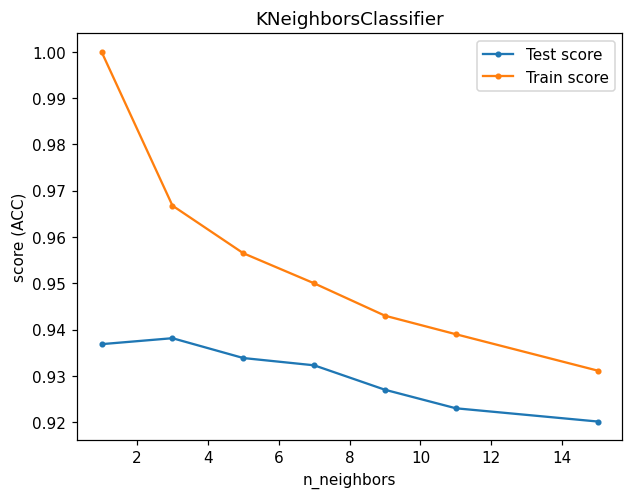

In [10]:
from sklearn.model_selection import GridSearchCV

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    {"n_neighbors": [1, 3, 5, 7, 9, 11, 15]},
    cv=3, return_train_score=True,
)
knn_grid.fit(X_sub, y_sub)
plot_tuning(knn_grid, "n_neighbors")
plt.show()

Best configuration:{'C': 0.1}
Best score (ACC):0.9035716694991193


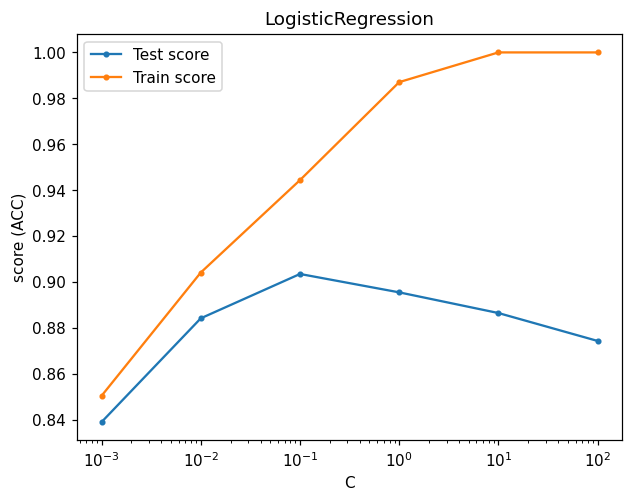

In [11]:
logreg_grid = GridSearchCV(
    LogisticRegression(max_iter=1000),
    {"C": [0.001, 0.01, 0.1, 1, 10, 100]},
    cv=3, return_train_score=True,
)
logreg_grid.fit(X_sub, y_sub)
plot_tuning(logreg_grid, "C")
plt.xscale("log")
plt.show()

Best configuration:{'C': 0.01}
Best score (ACC):0.8975720365487394


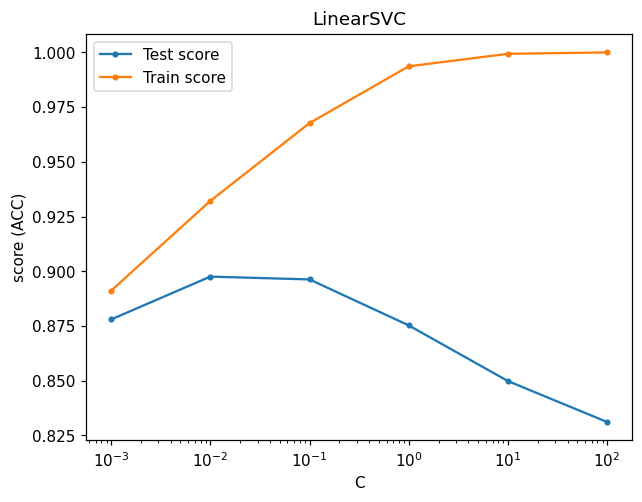

In [12]:
svm_grid = GridSearchCV(
    LinearSVC(max_iter=5000),
    {"C": [0.001, 0.01, 0.1, 1, 10, 100]},
    cv=3, return_train_score=True,
)
svm_grid.fit(X_sub, y_sub)
plot_tuning(svm_grid, "C")
plt.xscale("log")
plt.show()

**Resultados y discusion**

| Modelo | Mejor valor | Accuracy |
|---|---|---|
| k-NN | n_neighbors = 3 | 0.938 |
| Regresion Logistica | C = 0.1 | 0.904 |
| SVM Lineal | C = 0.01 | 0.898 |

**k-NN.** Con `n_neighbors = 1` el score de entrenamiento es 1.0 (cada punto es su propio vecino) mientras el de prueba baja: es overfitting puro. Desde `k = 3` el modelo generaliza mejor y alcanza su maximo; para valores grandes de `k` ambas curvas descienden juntas, senal de underfitting porque el promedio de demasiados vecinos borra el detalle local.

**Regresion Logistica y SVM Lineal.** El parametro `C` controla la regularizacion (es el inverso de su fuerza). Con `C` muy pequeno (0.001) el modelo queda demasiado restringido: train y test son bajos y casi iguales, es decir underfitting. Al subir `C` el score de entrenamiento crece hasta 1.0 pero el de prueba alcanza un maximo y luego cae, lo que indica overfitting. El punto optimo esta en la zona intermedia (C = 0.1 en la regresion logistica y C = 0.01 en el SVM).

El ajuste mejora de forma moderada a los modelos lineales respecto a su valor por defecto (C = 1) y casi no cambia a k-NN, cuyo k por defecto (5) ya estaba cerca del optimo. La franja de valores que de verdad mueve el rendimiento es la intermedia; en los extremos el modelo o memoriza o no aprende.

## 4. Análisis de clasificaciones erróneas y matriz de confusión

Para el modelo de Regresión Logística afinado ($C=0.1$):
- Dividimos los datos en train/test (75%/25%).
- Visualizamos ejemplos del conjunto de prueba donde el modelo predijo una clase equivocada para evaluar si son casos ambiguos o con trazo atípico.
- Construimos la matriz de confusión multiclase para identificar qué pares de dígitos concentran la mayor cantidad de errores.

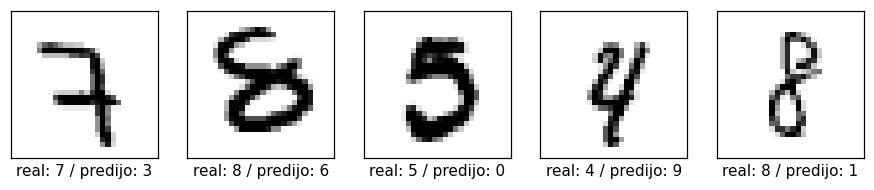

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

X_train, X_test, y_train, y_test = train_test_split(
    X_sub, y_sub, stratify=y_sub, random_state=0
)

logreg = LogisticRegression(C=0.1, max_iter=1000).fit(X_train, y_train)
y_pred = logreg.predict(X_test)

errores = np.where(y_pred != y_test)[0]
fig, axes = plt.subplots(1, 5, figsize=(10, 5))
for ax, i in zip(axes, errores[:5]):
    ax.imshow(X_test[i].reshape(28, 28), cmap=plt.cm.gray_r)
    ax.set_xlabel(f"real: {y_test[i]} / predijo: {y_pred[i]}")
    ax.set_xticks(()), ax.set_yticks(())
plt.show()

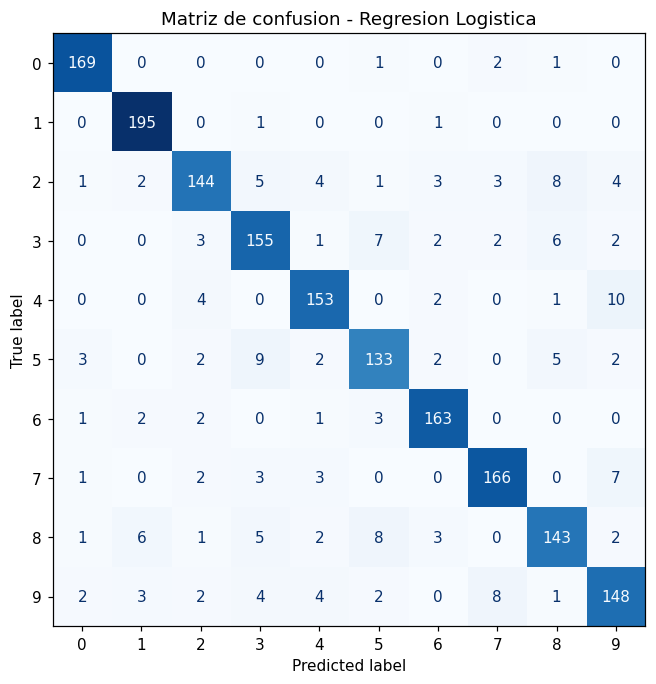

In [14]:
matriz = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(matriz, display_labels=[str(d) for d in range(10)])
fig, ax = plt.subplots(figsize=(7, 7))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Matriz de confusion - Regresion Logistica")
plt.show()

**Discusion**

Los ejemplos mal clasificados corresponden casi siempre a digitos escritos de forma descuidada o ambigua: cuatros abiertos que parecen nueves, cincos con el lazo poco cerrado que se confunden con treses, sietes de trazo curvo cercanos a nueves. No son fallos triviales del modelo, sino casos en los que incluso una persona dudaria.

En la matriz de confusion los errores se concentran fuera de la diagonal, en pares de digitos visualmente parecidos. Los mas frecuentes son **4 y 9**, **3 y 5**, **7 y 9** y **5 y 8**. Tiene sentido: todos comparten trazos (lazos cerrados, lineas verticales con gancho) que, sobre pixeles crudos y con una frontera lineal, son dificiles de distinguir. La gran mayoria de las predicciones cae en la diagonal, asi que el modelo acierta alrededor del 90%.

## 5. Interpretabilidad: Visualización espacial de los coeficientes del modelo

Recuperamos los pesos aprendidos por los clasificadores lineales (Regresión Logística y LinearSVC) para cada una de las 10 clases y los remodelamos a matrices de 28x28 píxeles:
- Coeficientes positivos (rojo): píxeles cuya presencia aporta evidencia a favor de esa clase.
- Coeficientes negativos (azul): píxeles que penalizan la pertenencia a esa clase.
- Comparación de las plantillas espaciales generadas por ambos clasificadores lineales.

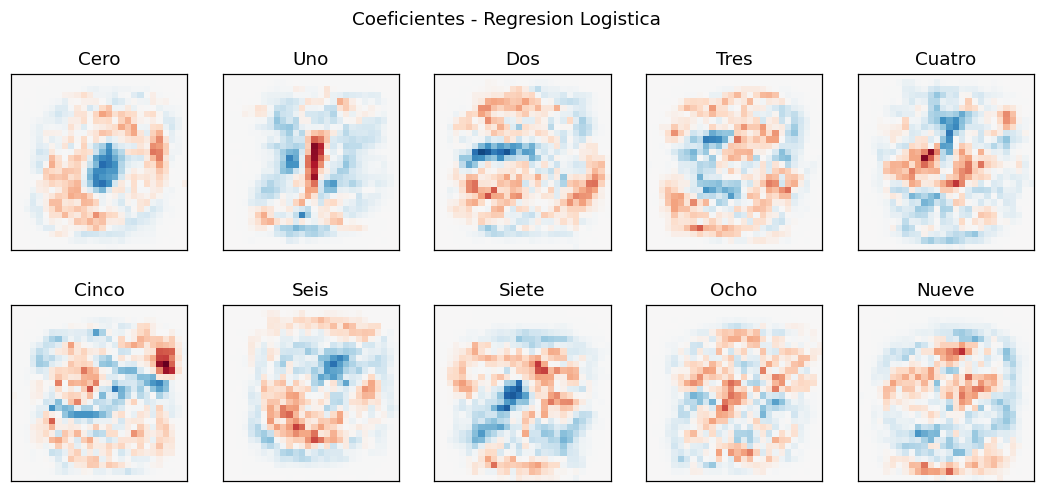

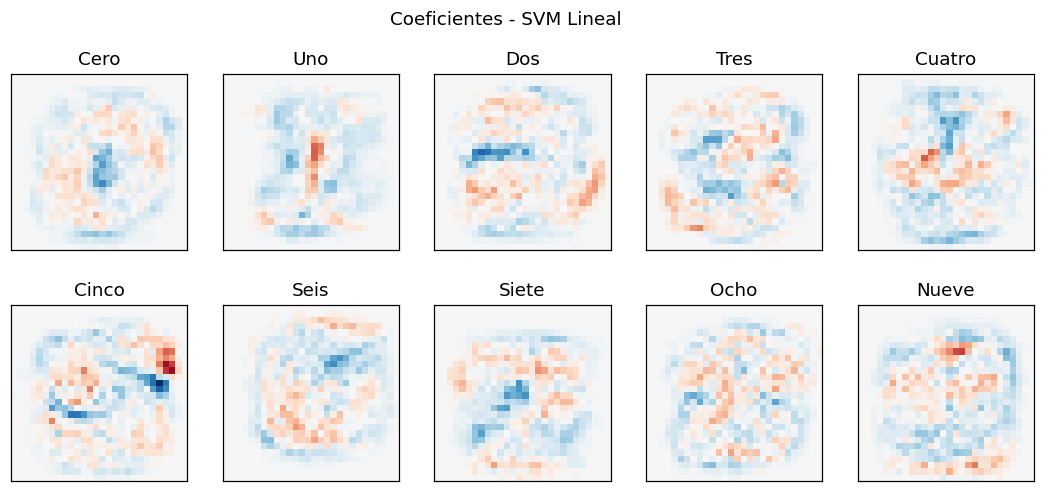

In [15]:
logreg_full = LogisticRegression(C=0.1, max_iter=1000).fit(X_sub, y_sub)
svm_full = LinearSVC(C=0.01, max_iter=5000).fit(X_sub, y_sub)

def plot_coeficientes(modelo, titulo):
    vmax = np.abs(modelo.coef_).max()
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for d, ax in enumerate(axes.ravel()):
        ax.imshow(modelo.coef_[d].reshape(28, 28), cmap="RdBu_r", vmin=-vmax, vmax=vmax)
        ax.set_title(mnist_classes[d])
        ax.set_xticks(()), ax.set_yticks(())
    fig.suptitle(titulo)
    plt.show()

plot_coeficientes(logreg_full, "Coeficientes - Regresion Logistica")
plot_coeficientes(svm_full, "Coeficientes - SVM Lineal")

**Interpretacion**

Cada subimagen son los 784 coeficientes de una clase reordenados a 28x28. En rojo los pesos positivos (pixeles que, al estar encendidos, empujan la prediccion hacia ese digito) y en azul los negativos (evidencia en contra).

Ambos modelos prestan atencion casi exclusivamente a la region central de la imagen, que es donde aparece el trazo; los bordes quedan en blanco (peso cercano a 0) porque alli nunca hay tinta. Se reconoce la "plantilla" de cada digito: el 0 muestra un anillo positivo con el centro negativo, y el 1 una franja vertical positiva en el centro.

Las diferencias entre regresion logistica y SVM lineal son pequenas, como cabia esperar al ser ambos modelos lineales sobre los mismos pixeles. La regularizacion mas fuerte del SVM (C = 0.01) produce mapas algo mas suaves y de menor magnitud, mientras que la regresion logistica genera patrones un poco mas marcados. En el fondo los dos aprenden la misma idea: comparar la imagen contra una plantilla por clase.

## 6. Caso de estudio en imágenes complejas: CIFAR-10

Para poner a prueba la generalización de estos métodos frente a imágenes del mundo real con iluminación, fondo y poses variables, aplicamos el mismo pipeline sobre el dataset [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) (60,000 imágenes a color de 32x32 píxeles en 10 clases de objetos: avión, automóvil, pájaro, gato, ciervo, perro, rana, caballo, barco, camión).

Analizamos las adaptaciones requeridas (conversión de RGB a escala de grises mediante combinación de luminancia, aplanado y normalización) y comparamos el desempeño de k-NN, Regresión Logística y LinearSVC.

In [16]:
# Load CIFAR-10 data set
from keras.datasets import cifar10
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

Visualización de ejemplos de cada clase de CIFAR-10 convertidos a escala de grises:

In [17]:
#X_train

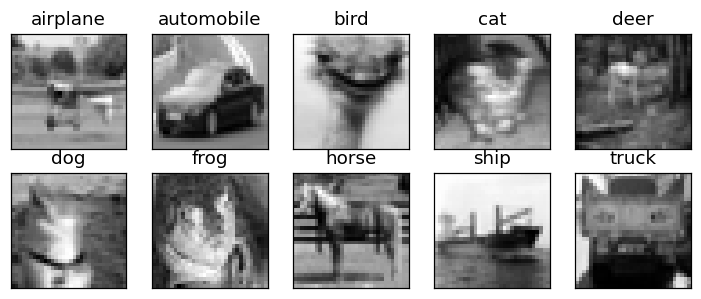

In [18]:
import numpy as np
import matplotlib.pyplot as plt

class_names = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
num_classes = len(class_names)

def a_grises(img):
    return np.dot(img[..., :3], [0.299, 0.587, 0.114])

fig = plt.figure(figsize=(8, 3))
for i in range(num_classes):
    ax = fig.add_subplot(2, 5, 1 + i, xticks=[], yticks=[])
    ax.set_title(class_names[i])
    idx = np.where(y_train[:, 0] == i)[0]
    ejemplo = X_train[np.random.choice(idx)]
    ax.imshow(a_grises(ejemplo), cmap="gray")
plt.show()

**Como adaptar el preprocesamiento (lectura, pre-tratamiento y plot)**

CIFAR-10 llega como imagenes en color de 32x32x3, mientras que MNIST eran 28x28 en escala de grises. Los ajustes necesarios para reutilizar el flujo del paso 1 son:

- **Lectura.** Ya no se descarga de OpenML con `get_data`; las imagenes vienen como tensores `(n, 32, 32, 3)` desde `keras.datasets.cifar10`. Las etiquetas llegan en una columna `(n, 1)`, asi que conviene aplanarlas con `.ravel()`.
- **Color a gris.** Para imitar MNIST convertimos cada imagen a un canal con la combinacion luminica `0.299*R + 0.587*G + 0.114*B`. Esto reduce de 3072 a 1024 valores por imagen, pero descarta el color, que en objetos naturales es una pista muy informativa.
- **Aplanado y escala.** Pasamos cada imagen de 32x32 a un vector de 1024 y dividimos entre 255 para dejar los valores en [0, 1], igual que con MNIST.
- **Plot.** `imshow` debe usar `cmap="gray"` sobre la imagen de un canal (celda anterior), en lugar de mostrar el RGB original.

In [19]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

gris = np.dot(X_train[..., :3], [0.299, 0.587, 0.114])
X_cifar = gris.reshape(len(gris), -1) / 255.0
y_cifar = y_train.ravel()

X_c, _, y_c, _ = train_test_split(
    X_cifar, y_cifar, train_size=0.10, stratify=y_cifar, random_state=42
)

clasificadores = {
    "k-NN": KNeighborsClassifier(),
    "Regresion Logistica": LogisticRegression(max_iter=1000),
    "SVM Lineal": LinearSVC(max_iter=5000),
}

for nombre, clf in clasificadores.items():
    scores = cross_val_score(clf, X_c, y_c, cv=3)
    print(f"{nombre:22s} accuracy = {scores.mean():.4f}  (+/- {scores.std():.4f})")

k-NN                   accuracy = 0.2218  (+/- 0.0073)
Regresion Logistica    accuracy = 0.2162  (+/- 0.0123)
SVM Lineal             accuracy = 0.1878  (+/- 0.0047)


**Resultados y discusion**

| Modelo | Accuracy (3-fold) |
|---|---|
| k-NN | 0.222 |
| Regresion Logistica | 0.216 |
| SVM Lineal | 0.188 |

Con la misma submuestra del 10% y validacion cruzada de 3 folds, los tres modelos apenas superan el azar (10% para 10 clases). El contraste con MNIST (cerca del 90%) es enorme y muestra el limite de estos metodos:

- En MNIST un digito es practicamente una plantilla de trazos sobre fondo blanco y casi alineada, por lo que comparar pixeles funciona bien. En CIFAR-10 cada clase aparece con fondos, poses, escalas e iluminaciones muy distintas; dos fotos de "perro" pueden no compartir casi ningun pixel, asi que la distancia en el espacio de pixeles (k-NN) y las fronteras lineales (regresion logistica, SVM) dejan de ser informativas.
- Pasar a escala de grises agrava el problema porque elimina el color, una de las pocas senales utiles (el azul del cielo en "avion/barco", el verde en "rana/ciervo").

**Adecuaciones realizadas:** convertir a gris, aplanar a 1024 dimensiones, escalar a [0, 1] y aplanar las etiquetas. La conclusion practica es que, para imagenes naturales, estos modelos sobre pixeles crudos no bastan: el camino razonable seria extraer caracteristicas (o usar redes convolucionales) antes de clasificar.